<font size=15 ><b> Tercer avance
</b></font>
 
 

Simulación de trayectorias


·&nbsp; **Diego Marquez Franco** &nbsp;

·&nbsp; **Pablo Rogelio Ramírez Alferes** &nbsp;

·&nbsp; **Carlos Gabriel Barrera Casasola**


# Simulación mediante densidades de transición

Recordemos que estamos estudiando el proceso estocástico

$$
dX_t=-\lambda X_t\,dt+\sqrt{\lambda X_t}\,dW_t,
\qquad X_0=x\geq 0,
$$

donde $\lambda>0$.

Nuestro objetivo es utilizar la distribución de transición del proceso para generar trayectorias en una partición del intervalo $[0,T]$.

## Obtención de la función generadora de momentos

Aplicando la fórmula de Itô a $X_t^n$ obtenemos

$$
dX_t^n=
\left(
-n\lambda X_t^n+
\frac{\lambda}{2}n(n-1)X_t^{n-1}
\right)dt
+n\sqrt{\lambda}X_t^{n-\frac12}dW_t.
$$

Definiendo $\mu_n(t)=\mathbb E[X_t^n]$, obtenemos el sistema

$$
\begin{cases}
\mu_1(t)=xe^{-\lambda t},\\[4pt]
\mu_n'(t)=-n\lambda\mu_n(t)+
\frac{\lambda}{2}n(n-1)\mu_{n-1}(t),\\[4pt]
\mu_n(0)=x^n.
\end{cases}
$$

Como se hizo en la Tarea II, definimos

$$
\nu_n(t)=e^{n\lambda t}\mu_n(t)
$$

y hacemos el cambio de variable

$$
u=e^{\lambda t}-1.
$$

Escribiendo $\widehat{\nu}_n(u)=\nu_n(t)$ obtenemos

$$
\begin{cases}
\widehat{\nu}_1(u)=x,\\[4pt]
\widehat{\nu}_n'(u)=
\frac12 n(n-1)\widehat{\nu}_{n-1}(u),\\[4pt]
\widehat{\nu}_n(0)=x^n.
\end{cases}
$$

Definimos la función generadora

$$
\widehat N(u,z)=
\sum_{n=1}^{\infty}
\widehat{\nu}_n(u)\frac{z^n}{n!}.
$$

Derivando respecto a $u$ y utilizando la recurrencia anterior llegamos a la ecuación diferencial parcial

$$
\frac{\partial\widehat N}{\partial u}
=
\frac{z^2}{2}
\frac{\partial\widehat N}{\partial z},
$$

con condición inicial

$$
\widehat N(0,z)=e^{xz}-1.
$$

Resolviendo por el método de las características obtenemos

$$
\widehat N(u,z)
=
\exp\left(\frac{2xz}{2-uz}\right)-1.
$$

Deshaciendo los cambios de variable, recuperamos la función generadora de momentos

$$
\boxed{
M(t,z)=
\exp\left(
\frac{2xz}
{2e^{\lambda t}-(e^{\lambda t}-1)z}
\right)
}.
$$

## Distribución del proceso

En la Tarea II se obtiene la distribución del proceso mediante la transformada inversa de Laplace.

Definimos los parámetros

$$
\Lambda_t(x)=\frac{2x}{e^{\lambda t}-1},
\qquad
K_t=\frac{2e^{\lambda t}}{e^{\lambda t}-1}.
$$

Con estos parámetros, la función generadora de momentos puede escribirse como

$$
M(t,z)=
\exp\left(
-\Lambda_t(x)
+
\frac{\Lambda_t(x)K_t}{K_t-z}
\right).
$$

Al invertir la transformada, obtenemos una distribución que contiene una masa puntual en cero y una parte continua.

Para $y>0$, la parte continua está dada por

$$
f_t(y\mid x)=
e^{-(K_t y+\Lambda_t(x))}
\sqrt{\frac{K_t\Lambda_t(x)}{y}}
I_1\left(2\sqrt{K_t\Lambda_t(x)y}\right),
$$

donde $I_1$ es la función de Bessel modificada de primera especie y orden uno.

Además,

$$
\mathbb P(X_t=0\mid X_0=x)
=e^{-\Lambda_t(x)}.
$$

Utilizando la expansión en serie de la función de Bessel, obtenemos

$$
f_t(y\mid x)
=
\sum_{n=1}^{\infty}
\frac{\Lambda_t(x)^n e^{-\Lambda_t(x)}}{n!}
\frac{K_t^n}{(n-1)!}
y^{n-1}e^{-K_t y}.
$$

Reconocemos en esta expresión una mezcla Poisson-Gamma.

En particular, podemos representar la distribución mediante

$$
N\sim\operatorname{Poisson}(\Lambda_t(x))
$$

y, condicionalmente a $N=n\geq1$,

$$
X_t\mid (X_0=x,N=n)
\sim\operatorname{Gamma}(n,K_t),
$$

donde $K_t$ es el parámetro de tasa de la distribución Gamma.

Si $N=0$, entonces $X_t=0$.

Equivalentemente,

$$
X_t\mid X_0=x
\overset{d}{=}
\sum_{j=1}^{N}Y_j,
$$

donde las $Y_j$ son independientes y tienen distribución exponencial con tasa $K_t$.

## Densidades de transición

Para obtener la distribución de transición entre dos tiempos $s<t$, escribimos $h=t-s$.

Por la homogeneidad temporal y la propiedad de Markov, la distribución condicional de $X_t$, dado $X_s=x$, se obtiene reemplazando $t$ por $h$ en las expresiones anteriores.

Por tanto,

$$
\Lambda_h(x)=\frac{2x}{e^{\lambda h}-1},
\qquad
K_h=\frac{2e^{\lambda h}}{e^{\lambda h}-1}.
$$

La distribución de transición tiene una masa en cero dada por

$$
\boxed{
\mathbb P(X_t=0\mid X_s=x)
=
e^{-\Lambda_h(x)}
}
$$

y una densidad sobre $y>0$ dada por

$$
\boxed{
p(s,x;t,y)=
e^{-(K_hy+\Lambda_h(x))}
\sqrt{\frac{K_h\Lambda_h(x)}{y}}
I_1\left(
2\sqrt{K_h\Lambda_h(x)y}
\right)
}.
$$

## Simulación mediante las distribuciones de transición

Consideramos una partición uniforme

$$
0=t_0<t_1<\cdots<t_m=T,
\qquad h=\frac{T}{m}.
$$

Suponiendo conocido el valor $X_{t_i}=x$, generamos

$$
N_i\sim\operatorname{Poisson}(\Lambda_h(x)).
$$

Después:

- Si $N_i=0$, tomamos $X_{t_{i+1}}=0$.
- Si $N_i\geq1$, generamos $X_{t_{i+1}}\sim\operatorname{Gamma}(N_i,K_h)$.

De esta manera obtenemos una trayectoria del proceso evaluada en los tiempos de la partición, utilizando directamente su ley de transición.


## Densidades

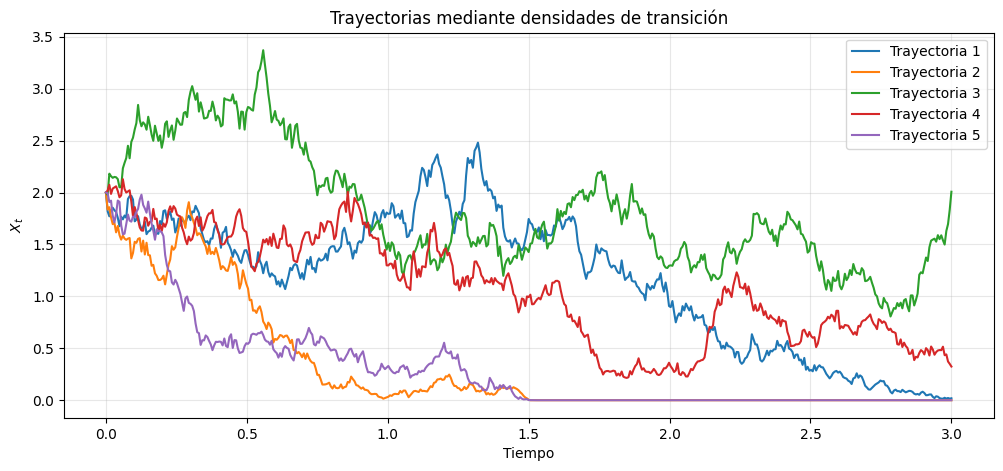

In [1]:

import numpy as np
import matplotlib.pyplot as plt

def trayectoria_transicion(T, pasos, lam, x0, rng):
    t = np.linspace(0, T, pasos + 1)
    X = np.zeros(pasos + 1)
    X[0] = x0

    h = T / pasos

    # Parametros de la distribucion Poisson-Gamma
    denominador = np.expm1(lam * h)
    K = 2 * np.exp(lam * h) / denominador

    for i in range(pasos):

        if X[i] == 0:
            X[i + 1] = 0
            continue

        Lambda = 2 * X[i] / denominador

        # Variable Poisson
        N = rng.poisson(Lambda)

        if N == 0:
            X[i + 1] = 0
        else:
            # Gamma con forma N y tasa K
            X[i + 1] = rng.gamma(
                shape=N,
                scale=1 / K
            )

    return t, X


# Parametros del ejemplo (modificables)
T = 3
pasos = 500
lam = 0.6
x0 = 2.0
n_trayectorias = 5

rng = np.random.default_rng(2026)

plt.figure(figsize=(12, 5))

for j in range(n_trayectorias):
    t, X = trayectoria_transicion(
        T, pasos, lam, x0, rng
    )

    plt.plot(t, X, label=f"Trayectoria {j + 1}")

plt.title("Trayectorias mediante densidades de transición")
plt.xlabel("Tiempo")
plt.ylabel(r"$X_t$")
plt.grid(alpha=0.3)
plt.legend()
plt.show()



## Simulación mediante Euler–Maruyama y Milstein

Recordemos que estamos estudiando el proceso estocástico

$$
dX_t=-\lambda X_t\,dt+\sqrt{\lambda X_t}\,dW_t,
\qquad X_0=x_0\geq 0,
$$

donde $\lambda>0$.

Para aproximar sus trayectorias, consideramos una partición uniforme del intervalo $[0,T]$:

$$
0=t_0<t_1<\cdots<t_m=T,
\qquad h=\frac{T}{m}.
$$

Los incrementos del movimiento browniano son independientes y satisfacen

$$
\Delta W_i=W_{t_{i+1}}-W_{t_i}
\sim \mathcal{N}(0,h).
$$

### Método de Euler–Maruyama

Para una ecuación diferencial estocástica de la forma

$$
dX_t=a(X_t)\,dt+b(X_t)\,dW_t,
$$

el esquema de Euler–Maruyama está dado por

$$
X_{i+1}^{E}
=
X_i^{E}
+
a(X_i^{E})h
+
b(X_i^{E})\Delta W_i.
$$

En nuestro caso,

$$
a(x)=-\lambda x,
\qquad
b(x)=\sqrt{\lambda x}.
$$

Por tanto,

$$
\boxed{
X_{i+1}^{E}
=
X_i^{E}
-\lambda X_i^{E}h
+\sqrt{\lambda X_i^{E}}\Delta W_i.
}
$$

### Método de Milstein

El esquema de Milstein incorpora un término adicional de corrección:

$$
X_{i+1}^{M}
=
X_i^{M}
+a(X_i^{M})h
+b(X_i^{M})\Delta W_i
+\frac12 b(X_i^{M})b'(X_i^{M})
\left((\Delta W_i)^2-h\right).
$$

Para nuestro proceso tenemos, cuando $x>0$,

$$
b(x)=\sqrt{\lambda x},
\qquad
b'(x)=\frac{\sqrt{\lambda}}{2\sqrt{x}}.
$$

De esta manera,

$$
\frac12 b(x)b'(x)
=
\frac{\lambda}{4}.
$$

Sustituyendo obtenemos

$$
\boxed{
\begin{aligned}
X_{i+1}^{M}
={}&X_i^{M}-\lambda X_i^{M}h\\
&+\sqrt{\lambda X_i^{M}}\Delta W_i\\
&+\frac{\lambda}{4}
\left((\Delta W_i)^2-h\right).
\end{aligned}
}
$$

### Tratamiento de la frontera en cero

Dado que el proceso original toma valores no negativos y el cero es un estado absorbente, debemos considerar que las aproximaciones numéricas pueden producir valores negativos.

Para evitarlo utilizaremos una proyección:

$$
X_{i+1}=\max\{0,\widetilde X_{i+1}\},
$$

donde $\widetilde X_{i+1}$ representa el valor propuesto por el método numérico.

Además, si $X_i=0$, definiremos $X_{i+1}=0$.

Esto constituye una modificación de los esquemas originales y puede introducir un sesgo numérico, especialmente cerca de la frontera. Para comparar ambos métodos utilizaremos los mismos incrementos brownianos en cada paso temporal

## Euler 

In [2]:

import numpy as np
import matplotlib.pyplot as plt

def simular_euler_milstein(lam, x0, T, pasos, rng):

    h = T / pasos
    t = np.linspace(0, T, pasos + 1)

    # Incrementos brownianos compartidos
    dW = np.sqrt(h) * rng.standard_normal(pasos)

    X_euler = np.zeros(pasos + 1)
    X_milstein = np.zeros(pasos + 1)

    X_euler[0] = x0
    X_milstein[0] = x0

    for i in range(pasos):

        # Euler-Maruyama
        x = X_euler[i]

        if x > 0:
            propuesta = (
                x - lam * x * h
                + np.sqrt(lam * x) * dW[i]
            )
            X_euler[i+1] = max(0, propuesta)

        # Milstein
        x = X_milstein[i]

        if x > 0:
            propuesta = (
                x - lam * x * h
                + np.sqrt(lam * x) * dW[i]
                + (lam / 4) * (dW[i]**2 - h)
            )
            X_milstein[i+1] = max(0, propuesta)

    return t, X_euler, X_milstein


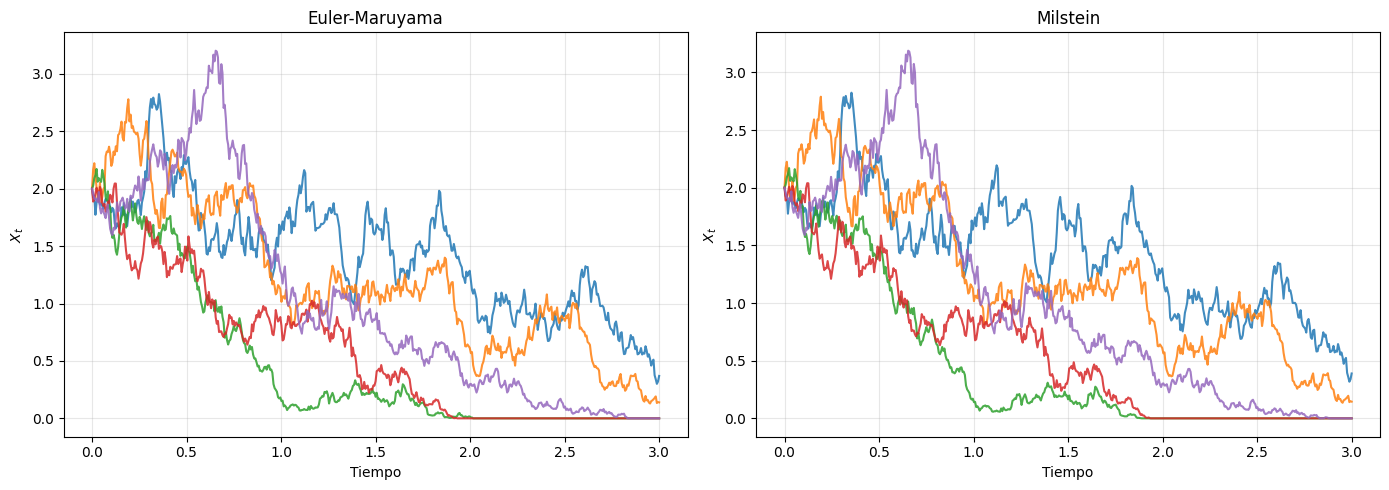

In [3]:

# Parámetros
lam = 0.6
x0 = 2.0
T = 3.0
pasos = 500
n_trayectorias = 5

rng = np.random.default_rng(2026)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for j in range(n_trayectorias):

    t, X_euler, X_milstein = simular_euler_milstein(
        lam, x0, T, pasos, rng
    )

    axes[0].plot(t, X_euler, alpha=0.85)
    axes[1].plot(t, X_milstein, alpha=0.85)

axes[0].set_title("Euler-Maruyama")
axes[1].set_title("Milstein")

for ax in axes:
    ax.set_xlabel("Tiempo")
    ax.set_ylabel(r"$X_t$")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Comparación de trayectorias: Euler–Maruyama, Milstein y densidades de transición

Una vez implementados los tres métodos, podemos comparar las trayectorias obtenidas para el proceso

$$
dX_t=-\lambda X_t\,dt+\sqrt{\lambda X_t}\,dW_t.
$$

Utilizaremos una misma partición temporal y las mismas condiciones iniciales.

Euler–Maruyama y Milstein compartirán los mismos incrementos brownianos, mientras que el método de densidades de transición generará una trayectoria independiente utilizando la representación Poisson-Gamma obtenida anteriormente.

Esta comparación permite observar las diferencias en el comportamiento de las trayectorias simuladas, aunque no constituye todavía una medición del error fuerte, ya que la trayectoria obtenida mediante las densidades de transición no está acoplada al mismo movimiento browniano.


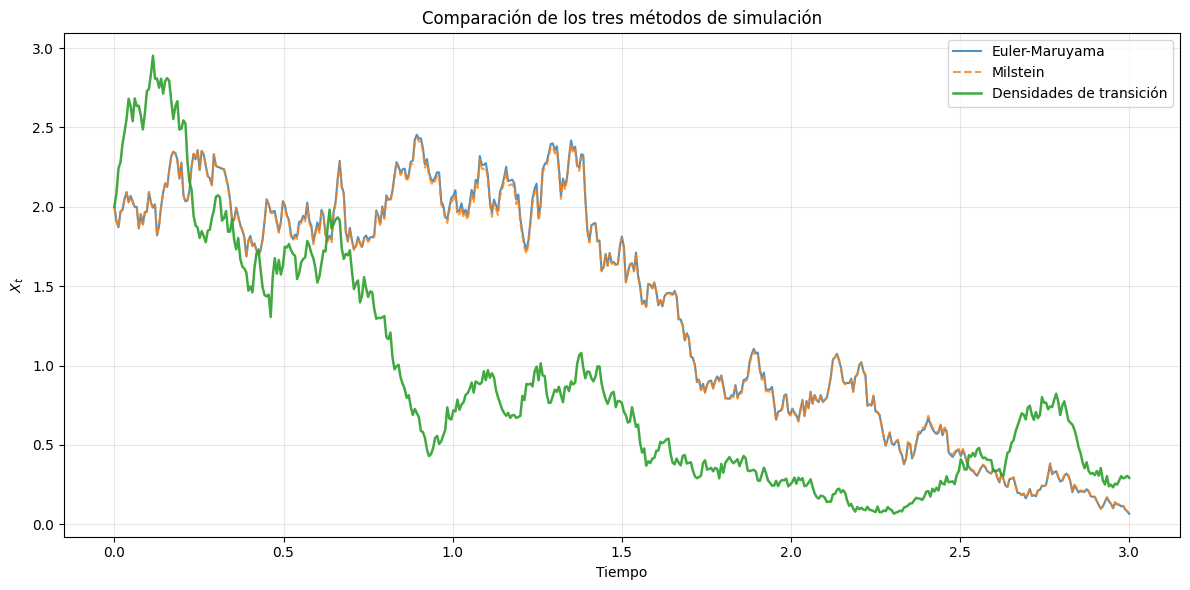

In [9]:

# Parámetros
lam = 0.6
x0 = 2.0
T = 3.0
pasos = 500

# Generadores independientes para reproducibilidad
rng_em = np.random.default_rng(123)
rng_trans = np.random.default_rng(456)

# Euler-Maruyama y Milstein
t, X_euler, X_milstein = simular_euler_milstein(
    lam, x0, T, pasos, rng_em
)

# Densidades de transición (Poisson-Gamma)
t_trans, X_trans = trayectoria_transicion(
    T, pasos, lam, x0, rng_trans
)

# Comparación gráfica
plt.figure(figsize=(12, 6))

plt.plot(
    t, X_euler,
    label="Euler-Maruyama",
    linewidth=1.5,
    alpha=0.8
)

plt.plot(
    t, X_milstein,
    label="Milstein",
    linewidth=1.5,
    linestyle="--",
    alpha=0.8
)

plt.plot(
    t_trans, X_trans,
    label="Densidades de transición",
    linewidth=1.8,
    alpha=0.9
)

plt.title("Comparación de los tres métodos de simulación")
plt.xlabel("Tiempo")
plt.ylabel(r"$X_t$")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



# 2. Estimación de momentos y comparación con los valores teóricos

En esta sección estimaremos los momentos del proceso

$$
dX_t=-\lambda X_t\,dt+\sqrt{\lambda X_t}\,dW_t,
\qquad X_0=x_0,
$$

a partir de las trayectorias generadas mediante Euler–Maruyama, Milstein y densidades de transición.

Como obtuvimos en la Tarea II, el momento de orden $n$ está dado por

$$
\boxed{
\mathbb E[X_t^n]
=
e^{-n\lambda t}
\sum_{i=0}^{n-1}
\binom{n}{i}
\binom{n-1}{i}
\frac{i!}{2^i}
x_0^{n-i}(e^{\lambda t}-1)^i
}
$$

En particular, la esperanza y la varianza son

$$
\mathbb E[X_t]=x_0e^{-\lambda t},
$$

$$
\operatorname{Var}(X_t)
=
x_0e^{-\lambda t}(1-e^{-\lambda t}).
$$

Para estimar los momentos mediante simulación, consideramos $N$ trayectorias independientes del proceso.

El estimador Monte Carlo del momento de orden $n$ es

$$
\widehat{\mu}_n(t)
=
\frac{1}{N}\sum_{j=1}^{N}(X_t^{(j)})^n.
$$

También estimaremos la varianza mediante la varianza muestral

$$
\widehat{\operatorname{Var}}(X_t)
=
\frac{1}{N-1}
\sum_{j=1}^N
\left(X_t^{(j)}-\overline X_t\right)^2,
$$

donde

$$
\overline X_t=\frac{1}{N}\sum_{j=1}^N X_t^{(j)}.
$$

Compararemos la media, la varianza y los momentos de orden tres y cuatro para evaluar la concordancia de los métodos numéricos con los resultados teóricos.


In [10]:

from math import comb, factorial
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def momento_teorico(t, n, lam, x0):
    """
    Calcula E[X_t^n] usando la fórmula de la Tarea II.
    """
    t = np.asarray(t)
    p = np.exp(-lam * t)
    q = 1 - p

    resultado = np.zeros_like(t, dtype=float)

    for i in range(n):
        coef = (
            comb(n, i)
            * comb(n - 1, i)
            * factorial(i) / (2**i)
        )

        resultado += (
            coef * x0**(n-i)
            * p**(n-i) * q**i
        )

    return resultado


# Parámetros del proceso
lam = 0.6
x0 = 2.0
T = 3.0
pasos = 500

t = np.linspace(0, T, pasos + 1)

# Momentos teóricos
m1 = momento_teorico(t, 1, lam, x0)
m2 = momento_teorico(t, 2, lam, x0)
m3 = momento_teorico(t, 3, lam, x0)
m4 = momento_teorico(t, 4, lam, x0)

# Varianza teórica
var_teorica = m2 - m1**2

teoricos = {
    "Media": m1,
    "Varianza": var_teorica,
    "Momento 3": m3,
    "Momento 4": m4
}


In [11]:

N = 3000  # Número de trayectorias

rng_em = np.random.default_rng(2026)
rng_trans = np.random.default_rng(2027)

# Matrices: filas = trayectorias, columnas = tiempos
X_euler = np.zeros((N, pasos + 1))
X_milstein = np.zeros((N, pasos + 1))
X_trans = np.zeros((N, pasos + 1))

for j in range(N):

    _, X_euler[j], X_milstein[j] = simular_euler_milstein(
        lam, x0, T, pasos, rng_em
    )

    _, X_trans[j] = trayectoria_transicion(
        T, pasos, lam, x0, rng_trans
    )

# Organizamos los resultados
simulaciones = {
    "Euler-Maruyama": X_euler,
    "Milstein": X_milstein,
    "Transición exacta": X_trans
}

# Estimación de momentos en cada instante temporal
estimaciones = {}

for nombre, X in simulaciones.items():

    estimaciones[nombre] = {
        "Media": np.mean(X, axis=0),
        "Varianza": np.var(X, axis=0, ddof=1),
        "Momento 3": np.mean(X**3, axis=0),
        "Momento 4": np.mean(X**4, axis=0)
    }

print(f"Se simularon {N} trayectorias por método.")


Se simularon 3000 trayectorias por método.


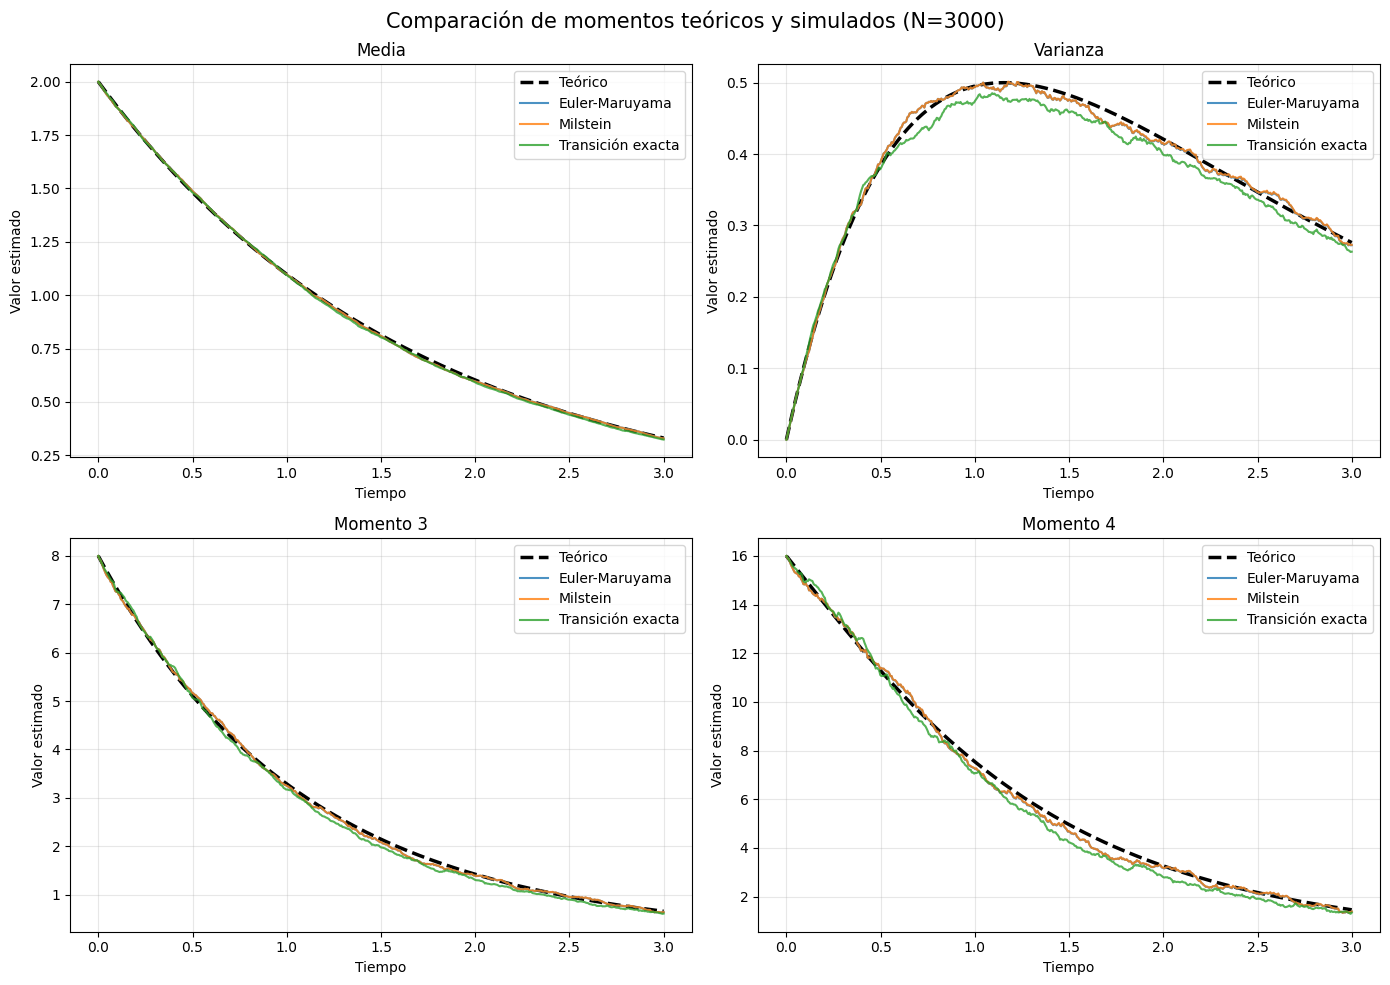

In [12]:

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, magnitud in zip(axes.flat, teoricos.keys()):

    # Valor teórico
    ax.plot(
        t,
        teoricos[magnitud],
        "k--",
        linewidth=2.5,
        label="Teórico"
    )

    # Estimaciones por cada método
    for metodo, resultados in estimaciones.items():
        ax.plot(
            t,
            resultados[magnitud],
            label=metodo,
            alpha=0.8
        )

    ax.set_title(magnitud)
    ax.set_xlabel("Tiempo")
    ax.set_ylabel("Valor estimado")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    f"Comparación de momentos teóricos y simulados (N={N})",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [13]:

filas = []

for magnitud, valor_teorico in teoricos.items():

    exacto = valor_teorico[-1]

    for metodo, resultados in estimaciones.items():

        estimado = resultados[magnitud][-1]
        error_abs = abs(estimado - exacto)

        error_rel = (
            100 * error_abs / abs(exacto)
            if abs(exacto) > 1e-12
            else np.nan
        )

        filas.append({
            "Magnitud": magnitud,
            "Método": metodo,
            "Teórico": exacto,
            "Estimado": estimado,
            "Error absoluto": error_abs,
            "Error relativo (%)": error_rel
        })

tabla_errores = pd.DataFrame(filas)

print(f"Comparación en T = {T}")
display(tabla_errores.round(5))


Comparación en T = 3.0


,Magnitud,Método,Teórico,Estimado,Error absoluto,Error relativo (%)
0,Media,Euler-Maruyama,0.33060,0.32849,0.00211,0.63759
1,Media,Milstein,0.33060,0.32868,0.00192,0.58078
2,Media,Transición exacta,0.33060,0.32332,0.00727,2.20020
3,Varianza,Euler-Maruyama,0.27595,0.27229,0.00366,1.32523
4,Varianza,Milstein,0.27595,0.27280,0.00316,1.14336
5,Varianza,Transición exacta,0.27595,0.26324,0.01271,4.60673
6,Momento 3,Euler-Maruyama,0.65532,0.63548,0.01984,3.02813
7,Momento 3,Milstein,0.65532,0.63756,0.01776,2.70985
8,Momento 3,Transición exacta,0.65532,0.60775,0.04757,7.25897
9,Momento 4,Euler-Maruyama,1.45503,1.38314,0.07189,4.94083



# 3. Influencia del número de trayectorias y del paso temporal

En esta sección estudiaremos cómo influyen el número de trayectorias simuladas y el tamaño del paso temporal en la precisión de las estimaciones de los momentos del proceso

$$
dX_t=-\lambda X_t\,dt+\sqrt{\lambda X_t}\,dW_t.
$$

### Influencia del número de trayectorias

Para estimar el momento de orden $n$ en un tiempo $T$, utilizamos el estimador Monte Carlo

$$
\widehat{\mu}_n(T)
=
\frac{1}{N}\sum_{j=1}^{N}(X_T^{(j)})^n.
$$

Cuando las trayectorias son independientes, el error estadístico de Monte Carlo suele disminuir proporcionalmente a

$$
\frac{1}{\sqrt{N}},
$$

siempre que exista la varianza de la variable que estamos promediando. Por tanto, esperamos que al aumentar $N$ las estimaciones se vuelvan más estables y, en ausencia de sesgo numérico, se aproximen a los valores teóricos.

### Influencia del paso temporal

Consideramos una partición uniforme de $[0,T]$:

$$
h=\frac{T}{m}.
$$

Los métodos de Euler–Maruyama y Milstein aproximan la dinámica del proceso mediante incrementos temporales. Por esta razón, modificar $h$ puede afectar la precisión de sus estimaciones. En cambio, el método de densidades de transición utiliza directamente la distribución condicional exacta del proceso, por lo que no introduce error de discretización en los instantes de la partición.

### Medición del error

Para comparar los métodos, consideraremos una magnitud teórica $\theta$ y su estimación $\widehat{\theta}$.

El error absoluto es

$$
E=|\widehat{\theta}-\theta|.
$$

Para obtener una medida más estable, repetiremos cada experimento $R$ veces y calcularemos el error cuadrático medio:

$$
\boxed{
RMSE=
\sqrt{
\frac{1}{R}
\sum_{r=1}^{R}
\left(\widehat{\theta}^{(r)}-\theta\right)^2
}.
}
$$

También estudiaremos el sesgo empírico:

$$
\operatorname{Sesgo}
=
\frac{1}{R}
\sum_{r=1}^{R}\widehat{\theta}^{(r)}
-\theta.
$$

Analizaremos estas cantidades para la media, la varianza y los momentos de órdenes tres y cuatro, utilizando los valores teóricos obtenidos en la Tarea II.


In [14]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def simular_finales(lam, x0, T, pasos, N, rng):

    h = T / pasos

    # Valores iniciales
    Xe = np.full(N, x0, dtype=float)
    Xm = np.full(N, x0, dtype=float)
    Xt = np.full(N, x0, dtype=float)

    # Parámetros Poisson-Gamma
    den = np.expm1(lam * h)
    K = 2 * np.exp(lam * h) / den

    for i in range(pasos):

        # Incrementos brownianos compartidos
        dW = np.sqrt(h) * rng.standard_normal(N)

        # Euler-Maruyama
        propuesta_e = (
            Xe - lam * Xe * h
            + np.sqrt(lam * Xe) * dW
        )

        Xe = np.maximum(propuesta_e, 0)

        # Milstein
        propuesta_m = (
            Xm - lam * Xm * h
            + np.sqrt(lam * Xm) * dW
            + (lam / 4) * (dW**2 - h)
        )

        Xm = np.where(
            Xm > 0,
            np.maximum(propuesta_m, 0),
            0
        )

        # Densidades de transición
        Lambda = 2 * Xt / den
        n = rng.poisson(Lambda)

        nuevo = np.zeros(N)
        positivos = n > 0

        nuevo[positivos] = rng.gamma(
            shape=n[positivos],
            scale=1 / K
        )

        Xt = nuevo

    return {
        "Euler-Maruyama": Xe,
        "Milstein": Xm,
        "Transición exacta": Xt
    }


In [15]:

# Parámetros
lam = 0.6
x0 = 2.0
T = 3.0

# Momentos teóricos en el tiempo final
m1 = float(momento_teorico(T, 1, lam, x0))
m2 = float(momento_teorico(T, 2, lam, x0))

teoria = {
    "Media": m1,
    "Varianza": m2 - m1**2,
    "Momento 3": float(momento_teorico(T, 3, lam, x0)),
    "Momento 4": float(momento_teorico(T, 4, lam, x0))
}

def estadisticos_finales(x):
    return {
        "Media": np.mean(x),
        "Varianza": np.var(x, ddof=1),
        "Momento 3": np.mean(x**3),
        "Momento 4": np.mean(x**4)
    }


def evaluar_configuracion(N, pasos, R, semillero):

    errores = {
        (metodo, magnitud): []
        for metodo in [
            "Euler-Maruyama",
            "Milstein",
            "Transición exacta"
        ]
        for magnitud in teoria
    }

    for r in range(R):

        rng = np.random.default_rng(
            semillero.integers(0, 2**32)
        )

        simulaciones = simular_finales(
            lam, x0, T, pasos, N, rng
        )

        for metodo, X in simulaciones.items():

            estimados = estadisticos_finales(X)

            for magnitud, valor in estimados.items():
                error = valor - teoria[magnitud]
                errores[(metodo, magnitud)].append(error)

    filas = []

    for (metodo, magnitud), lista in errores.items():

        e = np.array(lista)

        filas.append({
            "N": N,
            "pasos": pasos,
            "h": T / pasos,
            "Método": metodo,
            "Magnitud": magnitud,
            "RMSE": np.sqrt(np.mean(e**2)),
            "Sesgo": np.mean(e)
        })

    return pd.DataFrame(filas)


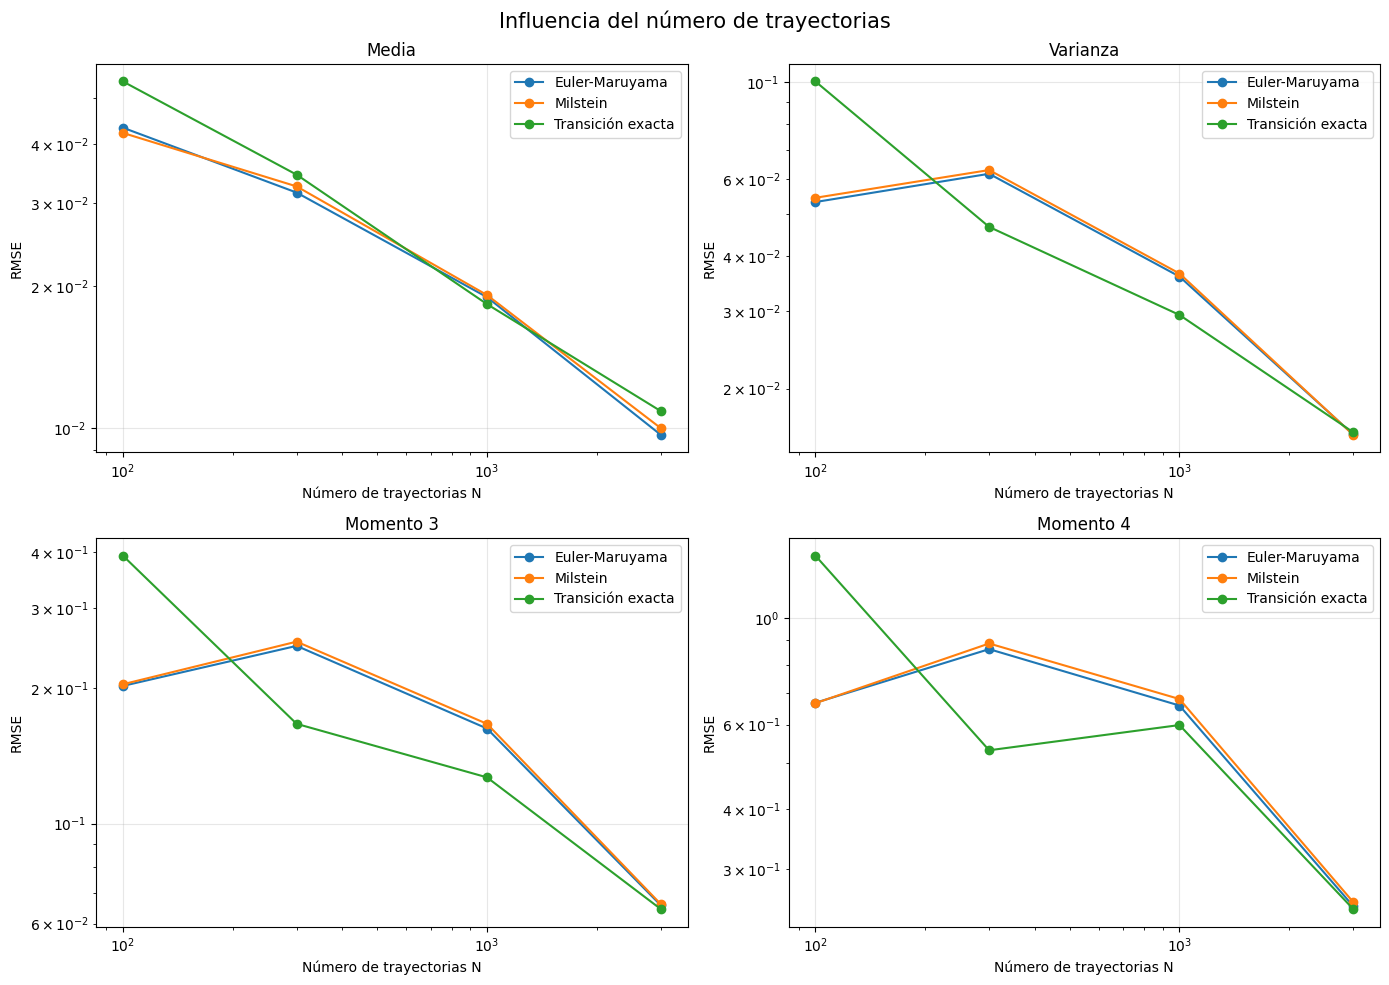

Método          Euler-Maruyama  Milstein  Transición exacta
Magnitud  N                                                
Media     100          0.04325   0.04216            0.05417
          300          0.03153   0.03249            0.03440
          1000         0.01895   0.01915            0.01832
          3000         0.00970   0.01002            0.01088
Momento 3 100          0.20194   0.20366            0.39259
          300          0.24775   0.25315            0.16636
          1000         0.16245   0.16638            0.12658
          3000         0.06590   0.06630            0.06463
Momento 4 100          0.66632   0.66506            1.35069
          300          0.86222   0.88599            0.53031
          1000         0.65751   0.67843            0.59868
          3000         0.25082   0.25584            0.24737
Varianza  100          0.05322   0.05441            0.10014
          300          0.06171   0.06293            0.04670
          1000         0.03600   0.03658            0.02943
          3000         0.01573   0.01570            0.01591

In [16]:

# Número de trayectorias
N_valores = [100, 300, 1000, 3000]

pasos_fijos = 200
R = 20  # Repeticiones independientes

semillero = np.random.default_rng(2026)

resultados_N = []

for N in N_valores:

    resultado = evaluar_configuracion(
        N=N,
        pasos=pasos_fijos,
        R=R,
        semillero=semillero
    )

    resultados_N.append(resultado)

tabla_N = pd.concat(
    resultados_N,
    ignore_index=True
)

# Visualización
magnitudes = [
    "Media", "Varianza",
    "Momento 3", "Momento 4"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, magnitud in zip(axes.flat, magnitudes):

    datos = tabla_N[
        tabla_N["Magnitud"] == magnitud
    ]

    for metodo, grupo in datos.groupby("Método"):

        grupo = grupo.sort_values("N")

        ax.loglog(
            grupo["N"],
            grupo["RMSE"],
            marker="o",
            label=metodo
        )

    ax.set_title(magnitud)
    ax.set_xlabel("Número de trayectorias N")
    ax.set_ylabel("RMSE")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "Influencia del número de trayectorias",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Tabla de errores
display(
    tabla_N.pivot_table(
        index=["Magnitud", "N"],
        columns="Método",
        values="RMSE"
    ).round(5)
)


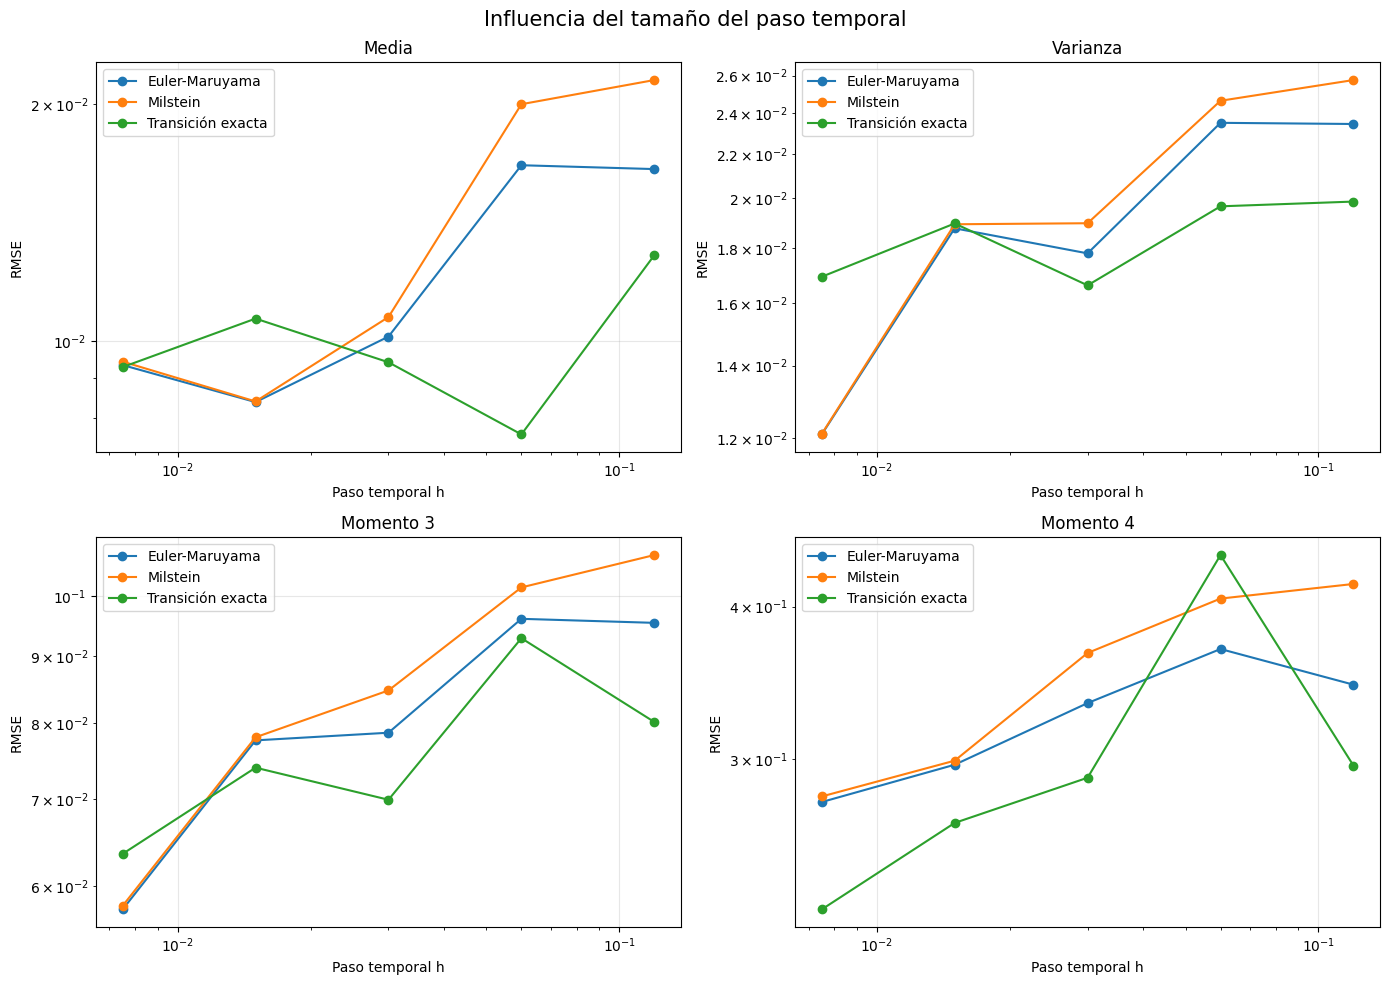

Método            Euler-Maruyama  Milstein  Transición exacta
Magnitud  h                                                  
Media     0.0075         0.00933   0.00943            0.00928
          0.0150         0.00838   0.00839            0.01069
          0.0300         0.01014   0.01074            0.00941
          0.0600         0.01672   0.01998            0.00762
          0.1200         0.01654   0.02144            0.01286
Momento 3 0.0075         0.05760   0.05797            0.06353
          0.0150         0.07759   0.07802            0.07395
          0.0300         0.07865   0.08473            0.06988
          0.0600         0.09613   0.10161            0.09291
          0.1200         0.09545   0.10757            0.08015
Momento 4 0.0075         0.27686   0.27979            0.22620
          0.0150         0.29699   0.29928            0.26619
          0.0300         0.33354   0.36652            0.28982
          0.0600         0.36926   0.40603            0.44070
          0.1200         0.34530   0.41735            0.29654
Varianza  0.0075         0.01209   0.01210            0.01692
          0.0150         0.01877   0.01893            0.01896
          0.0300         0.01779   0.01897            0.01661
          0.0600         0.02351   0.02464            0.01967
          0.1200         0.02345   0.02575            0.01987

In [17]:

# Número fijo de trayectorias
N_fijo = 2000

# Diferentes discretizaciones
pasos_valores = [25, 50, 100, 200, 400]

R = 20
semillero = np.random.default_rng(2027)

resultados_h = []

for pasos in pasos_valores:

    resultado = evaluar_configuracion(
        N=N_fijo,
        pasos=pasos,
        R=R,
        semillero=semillero
    )

    resultados_h.append(resultado)

tabla_h = pd.concat(
    resultados_h,
    ignore_index=True
)

# Visualización
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, magnitud in zip(axes.flat, magnitudes):

    datos = tabla_h[
        tabla_h["Magnitud"] == magnitud
    ]

    for metodo, grupo in datos.groupby("Método"):

        grupo = grupo.sort_values("h")

        ax.loglog(
            grupo["h"],
            grupo["RMSE"],
            marker="o",
            label=metodo
        )

    ax.set_title(magnitud)
    ax.set_xlabel("Paso temporal h")
    ax.set_ylabel("RMSE")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "Influencia del tamaño del paso temporal",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Tabla de errores
display(
    tabla_h.pivot_table(
        index=["Magnitud", "h"],
        columns="Método",
        values="RMSE"
    ).round(5)
)


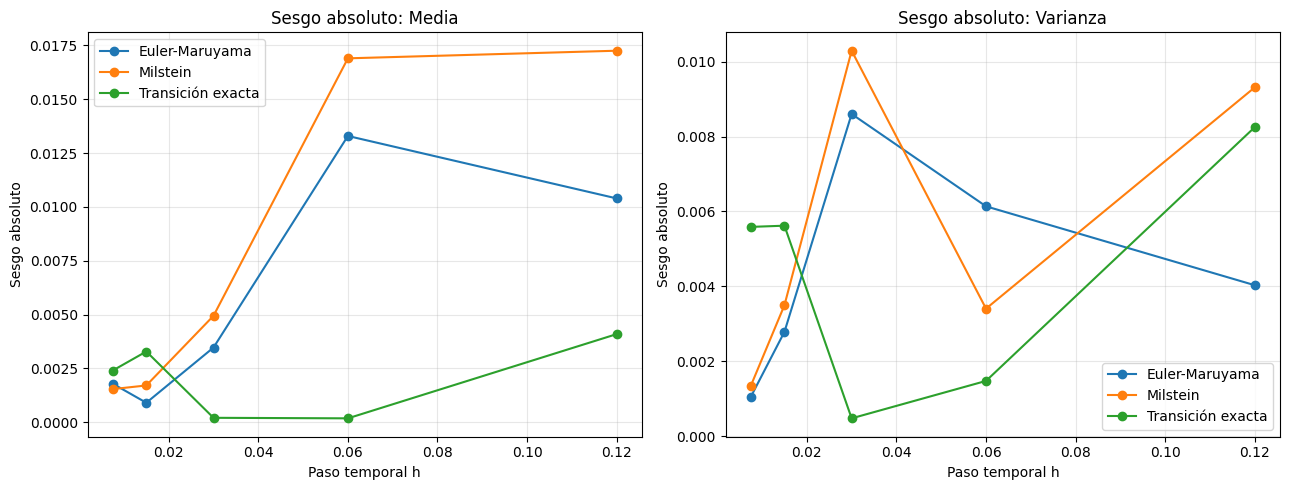

In [18]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, magnitud in zip(
    axes, ["Media", "Varianza"]
):

    datos = tabla_h[
        tabla_h["Magnitud"] == magnitud
    ]

    for metodo, grupo in datos.groupby("Método"):

        grupo = grupo.sort_values("h")

        ax.plot(
            grupo["h"],
            np.abs(grupo["Sesgo"]),
            marker="o",
            label=metodo
        )

    ax.set_title(f"Sesgo absoluto: {magnitud}")
    ax.set_xlabel("Paso temporal h")
    ax.set_ylabel("Sesgo absoluto")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()



### Interpretación de los resultados

Los experimentos permiten distinguir dos fuentes de error en la estimación de los momentos.

**1. Número de trayectorias**

Al incrementar $N$, esperamos una reducción del error estadístico de Monte Carlo. Este comportamiento se relaciona con la ley de los grandes números y con la escala $N^{-1/2}$ de las fluctuaciones de los promedios muestrales. Sin embargo, aumentar el número de trayectorias no elimina el posible sesgo de discretización de Euler–Maruyama y Milstein.

**2. Tamaño del paso temporal**

Al disminuir $h$, los métodos numéricos aproximan la dinámica del proceso con una discretización más fina. En el método de transición exacta, la distribución marginal de $X_T$ no depende del número de pasos empleados para llegar a $T$. Por esta razón, cualquier diferencia observada entre las estimaciones para distintos valores de $h$ corresponde al error estadístico de las muestras, salvo efectos de precisión computacional. En Euler–Maruyama y Milstein, la reducción de $h$ permite estudiar la disminución del sesgo de discretización. Es importante señalar que ambos métodos fueron modificados mediante una proyección a cero. Además, el coeficiente de difusión no es diferenciable en la frontera, por lo que no debemos asumir automáticamente las tasas de convergencia habituales para coeficientes suficientemente regulares.

**3. Comparación de los métodos**

El RMSE permite evaluar la precisión global de cada método para estimar los momentos, mientras que el sesgo empírico ayuda a identificar diferencias sistemáticas respecto de los valores teóricos. La interpretación definitiva dependerá de los errores obtenidos en las simulaciones.



# 4. Convergencia de las distribuciones marginales hacia la distribución estacionaria

Consideramos nuevamente el proceso estocástico

$$
dX_t=-\lambda X_t\,dt+\sqrt{\lambda X_t}\,dW_t,
\qquad X_0=x_0\geq 0.
$$

En la Tarea II estudiamos el comportamiento asintótico de este proceso y demostramos que

$$
X_t\xrightarrow[t\to\infty]{d}0.
$$

Esto significa que las distribuciones marginales de $X_t$ convergen débilmente a la medida de Dirac concentrada en cero:

$$
\boxed{
\mathcal L(X_t)\xrightarrow[t\to\infty]{}\delta_0.
}
$$

### Distribución estacionaria

El estado cero es absorbente, ya que tanto el coeficiente de deriva como el de difusión se anulan en dicho estado.

En consecuencia, si $X_0=0$, entonces $X_t=0$ para todo $t\geq0$.

Por lo tanto, la medida

$$
\boxed{\pi=\delta_0}
$$

es una distribución estacionaria del proceso.

### Convergencia de las distribuciones marginales

En la Tarea II obtuvimos que la distribución marginal tiene una representación Poisson-Gamma con parámetros

$$
\Lambda_t=\frac{2x_0}{e^{\lambda t}-1},
\qquad
K_t=\frac{2e^{\lambda t}}{e^{\lambda t}-1}.
$$

En particular, la probabilidad de que el proceso se encuentre exactamente en cero es

$$
\mathbb P(X_t=0)
=
\exp\left(
-\frac{2x_0}{e^{\lambda t}-1}
\right),\qquad t>0.
$$

Como

$$
\Lambda_t\xrightarrow[t\to\infty]{}0,
$$

tenemos que

$$
\boxed{
\mathbb P(X_t=0)\xrightarrow[t\to\infty]{}1.
}
$$

Por otro lado, sabemos que

$$
\mathbb E[X_t]=x_0e^{-\lambda t}.
$$

Por tanto,

$$
\lim_{t\to\infty}\mathbb E[X_t]=0.
$$

Dado que $X_t\geq0$, la desigualdad de Markov nos permite concluir que, para cualquier $\varepsilon>0$,

$$
\mathbb P(X_t>\varepsilon)
\leq
\frac{x_0e^{-\lambda t}}{\varepsilon}
\xrightarrow[t\to\infty]{}0.
$$

Esto confirma que el proceso converge en probabilidad hacia cero y, por tanto, también en distribución.

### Objetivo de la simulación

Para estudiar numéricamente esta convergencia:

1. Simularemos un conjunto de trayectorias durante un intervalo suficientemente largo.
2. Estimaremos las distribuciones marginales en diferentes instantes.
3. Compararemos la proporción de trayectorias absorbidas en cero con su valor teórico.
4. Analizaremos la concentración de las distribuciones marginales alrededor de cero.
5. Compararemos los resultados obtenidos mediante Euler–Maruyama, Milstein y densidades de transición.

Esperamos observar que, conforme aumenta el tiempo, una proporción cada vez mayor de las trayectorias alcanza el estado absorbente y la distribución marginal se aproxima a $\delta_0$.


In [19]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Parámetros
lam = 0.6
x0 = 2.0
T = 10.0
pasos = 1000
N = 5000

h = T / pasos

tiempos = np.array([0, 0.5, 1, 2, 4, 6, 10])
indices = {int(round(t / h)): j
           for j, t in enumerate(tiempos)}

rng_em = np.random.default_rng(2026)
rng_trans = np.random.default_rng(2027)

# Estados iniciales
Xe = np.full(N, x0, dtype=float)
Xm = np.full(N, x0, dtype=float)
Xt = np.full(N, x0, dtype=float)

# Almacenar muestras marginales en cada tiempo
marginales = {
    nombre: np.zeros((len(tiempos), N))
    for nombre in [
        "Euler-Maruyama",
        "Milstein",
        "Transición exacta"
    ]
}

for valores in marginales.values():
    valores[0] = x0

# Parámetros de transición exacta
den = np.expm1(lam * h)
K = 2 * np.exp(lam * h) / den

for i in range(1, pasos + 1):

    dW = np.sqrt(h) * rng_em.standard_normal(N)

    # Euler-Maruyama proyectado
    Xe = np.maximum(
        Xe - lam * Xe * h
        + np.sqrt(lam * Xe) * dW,
        0
    )

    # Milstein proyectado, con cero absorbente
    propuesta = (
        Xm - lam * Xm * h
        + np.sqrt(lam * Xm) * dW
        + (lam / 4) * (dW**2 - h)
    )

    Xm = np.where(Xm > 0, np.maximum(propuesta, 0), 0)

    # Transición exacta Poisson-Gamma
    Lambda = 2 * Xt / den
    n = rng_trans.poisson(Lambda)

    nuevo = np.zeros(N)
    positivos = n > 0

    nuevo[positivos] = rng_trans.gamma(
        shape=n[positivos],
        scale=1 / K
    )

    Xt = nuevo

    # Guardar las distribuciones marginales
    if i in indices:
        j = indices[i]

        marginales["Euler-Maruyama"][j] = Xe
        marginales["Milstein"][j] = Xm
        marginales["Transición exacta"][j] = Xt

print("Simulación terminada.")


Simulación terminada.


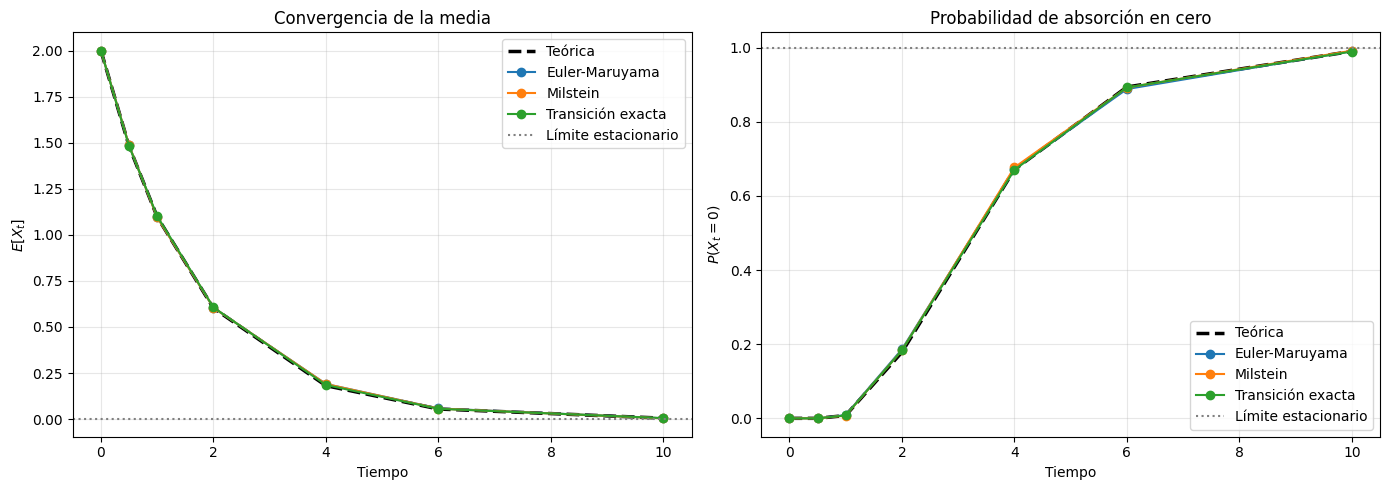

In [20]:

# Valores teóricos
media_teorica = x0 * np.exp(-lam * tiempos)

prob_cero_teorica = np.zeros_like(tiempos)

# Evitamos la división entre cero cuando t=0
positivos = tiempos > 0

prob_cero_teorica[positivos] = np.exp(
    -2 * x0 / np.expm1(lam * tiempos[positivos])
)

prob_cero_teorica[~positivos] = float(x0 == 0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Media
axes[0].plot(
    tiempos, media_teorica,
    "k--", linewidth=2.5, label="Teórica"
)

# Probabilidad de estar en cero
axes[1].plot(
    tiempos, prob_cero_teorica,
    "k--", linewidth=2.5, label="Teórica"
)

for metodo, X in marginales.items():

    media = np.mean(X, axis=1)
    prob_cero = np.mean(X == 0, axis=1)

    axes[0].plot(
        tiempos, media,
        marker="o", label=metodo
    )

    axes[1].plot(
        tiempos, prob_cero,
        marker="o", label=metodo
    )

axes[0].axhline(
    0, color="gray", linestyle=":",
    label="Límite estacionario"
)

axes[1].axhline(
    1, color="gray", linestyle=":",
    label="Límite estacionario"
)

axes[0].set_title("Convergencia de la media")
axes[0].set_ylabel(r"$E[X_t]$")

axes[1].set_title("Probabilidad de absorción en cero")
axes[1].set_ylabel(r"$P(X_t=0)$")

for ax in axes:
    ax.set_xlabel("Tiempo")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


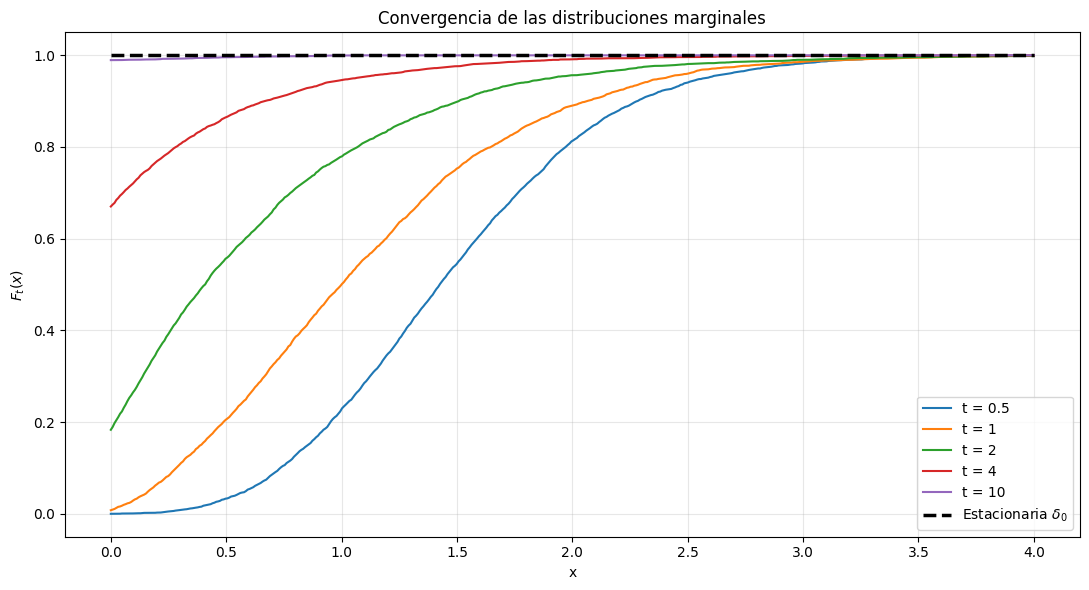

In [21]:

# Dominio para la función de distribución
y = np.linspace(0, 4, 500)

# Tiempos a comparar
tiempos_grafica = [0.5, 1, 2, 4, 10]

plt.figure(figsize=(11, 6))

for tiempo in tiempos_grafica:

    j = np.argmin(np.abs(tiempos - tiempo))

    muestra = marginales["Transición exacta"][j]
    muestra_ordenada = np.sort(muestra)

    # Función de distribución empírica
    F_empirica = (
        np.searchsorted(
            muestra_ordenada, y, side="right"
        ) / N
    )

    plt.plot(
        y, F_empirica,
        label=f"t = {tiempo}"
    )

# Distribución estacionaria: delta en cero
plt.plot(
    y, np.ones_like(y),
    "k--", linewidth=2.5,
    label=r"Estacionaria $\delta_0$"
)

plt.title("Convergencia de las distribuciones marginales")
plt.xlabel("x")
plt.ylabel(r"$F_t(x)$")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [22]:

filas = []

for j, tiempo in enumerate(tiempos):

    for metodo, X in marginales.items():

        muestra = X[j]

        filas.append({
            "Tiempo": tiempo,
            "Método": metodo,
            "P(X=0) teórica": prob_cero_teorica[j],
            "P(X=0) estimada": np.mean(muestra == 0),
            "Media teórica": media_teorica[j],
            "Media estimada": np.mean(muestra)
        })

tabla_estacionaria = pd.DataFrame(filas)

display(tabla_estacionaria.round(5))


,Tiempo,Método,P(X=0) teórica,P(X=0) estimada,Media teórica,Media estimada
0,0.0,Euler-Maruyama,0.00000,0.0000,2.00000,2.00000
1,0.0,Milstein,0.00000,0.0000,2.00000,2.00000
2,0.0,Transición exacta,0.00000,0.0000,2.00000,2.00000
3,0.5,Euler-Maruyama,0.00001,0.0000,1.48164,1.48579
4,0.5,Milstein,0.00001,0.0000,1.48164,1.48569
5,0.5,Transición exacta,0.00001,0.0000,1.48164,1.48265
6,1.0,Euler-Maruyama,0.00771,0.0088,1.09762,1.09574
7,1.0,Milstein,0.00771,0.0076,1.09762,1.09573
8,1.0,Transición exacta,0.00771,0.0078,1.09762,1.10142
9,2.0,Euler-Maruyama,0.17834,0.1860,0.60239,0.60454



### Interpretación de la convergencia estacionaria

El proceso estudiado tiene como distribución estacionaria la medida de Dirac $\delta_0$, las simulaciones permiten analizar esta convergencia desde dos perspectivas complementarias.

**Probabilidad de absorción.** La proporción de trayectorias que alcanzan el estado cero aumenta con el tiempo. El método de transición exacta permite contrastar directamente esta proporción con la expresión teórica

$$
\mathbb P(X_t=0)
=
\exp\left(
-\frac{2x_0}{e^{\lambda t}-1}
\right).
$$

**Distribuciones marginales.** Las funciones de distribución acumulada permiten observar cómo la probabilidad se concentra progresivamente en cero. Conforme aumenta $t$, las distribuciones marginales se aproximan a la distribución degenerada $\delta_0$.

**Comparación de los métodos.** Las simulaciones mediante Euler–Maruyama y Milstein también permiten estudiar este comportamiento. Sin embargo, la proyección a cero introducida en ambos métodos puede modificar la probabilidad de absorción, generando diferencias respecto de la transición exacta. Por tanto, la convergencia observada numéricamente es consistente con el comportamiento asintótico establecido en la Tarea II, aunque la magnitud de los errores de cada aproximación debe evaluarse a partir de las simulaciones.



## 5. Eficiencia computacional de los métodos de simulación

En esta sección compararemos la eficiencia computacional de los tres métodos implementados: Euler–Maruyama, Milstein y densidades de transición. El objetivo es estudiar la relación entre el costo computacional y la precisión de las estimaciones. Para realizar una comparación justa, utilizaremos los mismos parámetros del proceso, el mismo número de trayectorias $N$ y el mismo número de pasos temporales $m$.

### Tiempo de ejecución

Mediremos el tiempo necesario para generar $N$ trayectorias en el intervalo $[0,T]$. Cada experimento será repetido varias veces y utilizaremos la mediana de los tiempos de ejecución para reducir el efecto de fluctuaciones en el rendimiento del equipo. También calcularemos el tiempo por cada mil trayectorias simuladas.

### Relación entre precisión y costo computacional

Como medida de precisión utilizaremos el error cuadrático medio (RMSE) de las estimaciones de la media y la varianza en el tiempo final $T$.

Los valores teóricos son

$$
\mathbb E[X_T]=x_0e^{-\lambda T},
$$

$$
\operatorname{Var}(X_T)
=
x_0e^{-\lambda T}(1-e^{-\lambda T}).
$$

Para una magnitud teórica $\theta$, calcularemos

$$
RMSE=
\sqrt{
\frac1R\sum_{r=1}^{R}
(\widehat{\theta}^{(r)}-\theta)^2
}.
$$

Compararemos el RMSE con el tiempo de ejecución para analizar qué métodos ofrecen mayor precisión por unidad de tiempo computacional.

### Consideraciones sobre los métodos

Euler–Maruyama requiere evaluar los coeficientes de deriva y difusión y generar incrementos normales. Milstein realiza estas mismas operaciones e incorpora un término de corrección adicional. El método de densidades de transición utiliza la representación Poisson-Gamma, por lo que requiere generar variables Poisson y Gamma en cada paso. Aunque este último método puede requerir operaciones aleatorias más costosas, tiene la ventaja de reproducir exactamente la distribución de transición del proceso en los tiempos discretizados. La comparación experimental permitirá estudiar estas diferencias.


In [23]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

# Euler-Maruyama
def eficiencia_euler(lam, x0, T, pasos, N, rng):

    h = T / pasos
    X = np.full(N, x0, dtype=float)

    for i in range(pasos):
        dW = np.sqrt(h) * rng.standard_normal(N)

        X = np.maximum(
            X - lam * X * h
            + np.sqrt(lam * X) * dW,
            0
        )

    return X


# Milstein
def eficiencia_milstein(lam, x0, T, pasos, N, rng):

    h = T / pasos
    X = np.full(N, x0, dtype=float)

    for i in range(pasos):
        dW = np.sqrt(h) * rng.standard_normal(N)

        propuesta = (
            X - lam * X * h
            + np.sqrt(lam * X) * dW
            + (lam / 4) * (dW**2 - h)
        )

        X = np.where(
            X > 0,
            np.maximum(propuesta, 0),
            0
        )

    return X


# Densidades de transición (Poisson-Gamma)
def eficiencia_transicion(lam, x0, T, pasos, N, rng):

    h = T / pasos
    X = np.full(N, x0, dtype=float)

    den = np.expm1(lam * h)
    K = 2 * np.exp(lam * h) / den

    for i in range(pasos):

        Lambda = 2 * X / den

        n = rng.poisson(Lambda)

        nuevo = np.zeros(N)
        positivos = n > 0

        nuevo[positivos] = rng.gamma(
            shape=n[positivos],
            scale=1 / K
        )

        X = nuevo

    return X


metodos = {
    "Euler-Maruyama": eficiencia_euler,
    "Milstein": eficiencia_milstein,
    "Transición exacta": eficiencia_transicion
}


In [24]:

# Parámetros del proceso
lam = 0.6
x0 = 2.0
T = 3.0

N = 3000
pasos_valores = [25, 50, 100, 200, 400]
R = 8

# Valores teóricos
media_teorica = x0 * np.exp(-lam * T)
var_teorica = (
    x0 * np.exp(-lam * T)
    * (1 - np.exp(-lam * T))
)

# Calentamiento de las funciones
for k, funcion in enumerate(metodos.values()):
    funcion(
        lam, x0, T, 10, 100,
        np.random.default_rng(100 + k)
    )

resultados = []

for pasos in pasos_valores:

    for k, (nombre, funcion) in enumerate(metodos.items()):

        tiempos = []
        estimaciones_media = []
        estimaciones_var = []

        for r in range(R):

            rng = np.random.default_rng(
                2026 + pasos * 100 + 10 * r + k
            )

            inicio = time.perf_counter()

            X = funcion(
                lam, x0, T, pasos, N, rng
            )

            duracion = time.perf_counter() - inicio

            tiempos.append(duracion)
            estimaciones_media.append(np.mean(X))
            estimaciones_var.append(np.var(X, ddof=1))

        # Medidas de precisión
        errores_media = (
            np.array(estimaciones_media) - media_teorica
        )

        errores_var = (
            np.array(estimaciones_var) - var_teorica
        )

        tiempo_mediano = np.median(tiempos)

        resultados.append({
            "Método": nombre,
            "Pasos": pasos,
            "h": T / pasos,
            "Tiempo (s)": tiempo_mediano,
            "ms por 1000 trayectorias":
                tiempo_mediano * 1000 / (N / 1000),
            "RMSE media": np.sqrt(
                np.mean(errores_media**2)
            ),
            "RMSE varianza": np.sqrt(
                np.mean(errores_var**2)
            )
        })

tabla_eficiencia = pd.DataFrame(resultados)

display(tabla_eficiencia.round(5))


,Método,Pasos,h,Tiempo (s),ms por 1000 trayectorias,RMSE media,RMSE varianza
0,Euler-Maruyama,25,0.1200,0.00201,0.66878,0.01598,0.01132
1,Milstein,25,0.1200,0.00304,1.01273,0.02213,0.01528
2,Transición exacta,25,0.1200,0.01196,3.98767,0.00499,0.01074
3,Euler-Maruyama,50,0.0600,0.00457,1.52248,0.00546,0.01521
4,Milstein,50,0.0600,0.00588,1.95895,0.01070,0.01033
5,Transición exacta,50,0.0600,0.02300,7.66725,0.01247,0.02054
6,Euler-Maruyama,100,0.0300,0.00789,2.62972,0.00976,0.01326
7,Milstein,100,0.0300,0.01008,3.35958,0.00977,0.01380
8,Transición exacta,100,0.0300,0.03768,12.55940,0.01179,0.01489
9,Euler-Maruyama,200,0.0150,0.01613,5.37778,0.00740,0.01055


In [25]:

def transicion_final_directa(lam, x0, T, N, rng):

    if T == 0:
        return np.full(N, x0, dtype=float)

    den = np.expm1(lam * T)
    Lambda = 2 * x0 / den
    K = 2 * np.exp(lam * T) / den

    n = rng.poisson(Lambda, size=N)

    X = np.zeros(N)
    positivos = n > 0

    X[positivos] = rng.gamma(
        shape=n[positivos],
        scale=1 / K
    )

    return X


# Comparación de dos formas de utilizar
# la transición exacta

N_prueba = 3000
pasos_prueba = 200
R_prueba = 8

tiempos_pasos = []
tiempos_directa = []

for r in range(R_prueba):

    rng1 = np.random.default_rng(3000 + r)
    rng2 = np.random.default_rng(4000 + r)

    inicio = time.perf_counter()

    X_pasos = eficiencia_transicion(
        lam, x0, T, pasos_prueba, N_prueba, rng1
    )

    tiempos_pasos.append(
        time.perf_counter() - inicio
    )

    inicio = time.perf_counter()

    X_directa = transicion_final_directa(
        lam, x0, T, N_prueba, rng2
    )

    tiempos_directa.append(
        time.perf_counter() - inicio
    )

comparacion = pd.DataFrame({
    "Procedimiento": [
        "Transición paso a paso",
        "Transición directa a T"
    ],
    "Tiempo mediano (s)": [
        np.median(tiempos_pasos),
        np.median(tiempos_directa)
    ]
})

display(comparacion.round(6))


,Procedimiento,Tiempo mediano (s)
0,Transición paso a paso,0.062709
1,Transición directa a T,0.000304



### Ventajas y limitaciones de los métodos

**Euler–Maruyama**

Su principal ventaja es la simplicidad de implementación y el bajo costo computacional por paso temporal. Solamente requiere evaluar los coeficientes de la ecuación y generar incrementos normales. Sin embargo, introduce error de discretización y puede generar valores negativos, incompatibles con el espacio de estados del proceso. Por esta razón utilizamos una proyección a cero, que puede modificar las propiedades estadísticas de la aproximación.

**Milstein**

El método de Milstein incorpora un término de corrección que considera la variación del coeficiente de difusión. Esto puede mejorar la aproximación de las trayectorias respecto al método de Euler–Maruyama. Su principal limitación es que requiere operaciones adicionales y la derivada del coeficiente de difusión. En nuestro proceso, dicha derivada es singular en cero, por lo que no podemos aplicar directamente los resultados habituales de convergencia de Milstein sin condiciones adicionales.Además, utilizamos una proyección a cero para preservar la no negatividad.

**Densidades de transición**

Su principal ventaja es que permite generar valores del proceso utilizando su distribución condicional exacta, evitando el error de discretización en los tiempos considerados. Esto resulta particularmente útil para comparar momentos teóricos y simulados, así como para estudiar la absorción en cero y el comportamiento asintótico. Su limitación es que requiere conocer explícitamente la distribución de transición, algo que no siempre es posible para procesos estocásticos generales. En nuestro caso, la representación Poisson-Gamma facilita la implementación, aunque las simulaciones de variables Poisson y Gamma pueden resultar computacionalmente más costosas por paso que las operaciones de Euler o Milstein. Una ventaja adicional aparece cuando solamente interesa la distribución marginal en un tiempo final: en ese caso podemos generar muestras directamente, sin recorrer toda la partición temporal.

### Conclusión

La comparación de eficiencia debe considerar simultáneamente el tiempo de ejecución y el error de estimación. Un método de menor costo computacional no necesariamente proporciona estimaciones más precisas, mientras que un método más costoso puede compensar ese tiempo al reducir el error numérico. Para nuestro proceso, las densidades de transición constituyen una referencia especialmente útil porque conocemos su distribución exacta. Euler–Maruyama y Milstein permiten estudiar las ventajas y limitaciones de los esquemas de aproximación numérica, especialmente en presencia de una frontera absorbente. Los resultados experimentales permitirán determinar qué método ofrece la mejor relación entre precisión y costo computacional para los parámetros y discretizaciones utilizados.


# 6. Análisis de sensibilidad de los parámetros

Consideremos el proceso estocástico

$$
dX_t=-\lambda X_t\,dt+\sqrt{\lambda X_t}\,dW_t,
\qquad X_0=x_0\geq0,
$$

donde $\lambda>0$.

En esta sección estudiaremos cómo influyen los valores de $\lambda$ y $x_0$ sobre el comportamiento del proceso.

### Sensibilidad respecto a $\lambda$

El parámetro $\lambda$ aparece tanto en el coeficiente de deriva como en el de difusión:

$$
a(x)=-\lambda x,
\qquad
b(x)=\sqrt{\lambda x}.
$$

Por tanto, modificar $\lambda$ afecta simultáneamente la intensidad del decaimiento y la amplitud de las fluctuaciones estocásticas.

Para estudiar su influencia, consideraremos distintos valores de $\lambda$, manteniendo fija la condición inicial $x_0$.

### Sensibilidad respecto a $x_0$

La condición inicial determina el valor desde el cual comienza el proceso. Estudiaremos cómo cambia su comportamiento al considerar diferentes valores de $x_0$, manteniendo fijo $\lambda$.

### Magnitudes de interés

En la Tarea II obtuvimos expresiones teóricas para los momentos y la distribución del proceso. En particular, la media está dada por

$$
\mathbb E[X_t]=x_0e^{-\lambda t},
$$

y la varianza por

$$
\operatorname{Var}(X_t)
=
x_0e^{-\lambda t}(1-e^{-\lambda t}).
$$

Además, la probabilidad de absorción en cero es

$$
\mathbb P(X_t=0)=
\exp\left(
-\frac{2x_0}{e^{\lambda t}-1}
\right),
\qquad t>0.
$$

Estas expresiones permiten analizar teóricamente la sensibilidad del proceso.

### Experimentos numéricos

Realizaremos dos experimentos:

1. Variar $\lambda$ manteniendo fijo $x_0$.
2. Variar $x_0$ manteniendo fijo $\lambda$.

En ambos casos mantendremos constantes el horizonte temporal, el tamaño del paso y el número de trayectorias. Compararemos las estimaciones obtenidas mediante Euler–Maruyama, Milstein y densidades de transición con sus valores teóricos. El objetivo es identificar qué magnitudes son más sensibles a los cambios de los parámetros y determinar si los métodos numéricos reproducen correctamente estas variaciones.


In [26]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Parámetros de referencia
lam_base = 0.6
x0_base = 2.0

T = 3.0
pasos = 300
N = 5000

# Valores a estudiar
lambda_valores = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2]
x0_valores = [0.5, 1.0, 2.0, 3.0, 4.0, 5.0]

experimentos = {
    "lambda": lambda_valores,
    "x0": x0_valores
}

resultados_sensibilidad = []

for parametro, valores in experimentos.items():

    for j, valor in enumerate(valores):

        # Modificamos solamente un parámetro
        if parametro == "lambda":
            lam = valor
            x0 = x0_base
        else:
            lam = lam_base
            x0 = valor

        rng = np.random.default_rng(
            2026 + 1000 * (parametro == "x0") + j
        )

        simulaciones = simular_finales(
            lam, x0, T, pasos, N, rng
        )

        # Valores teóricos
        p = np.exp(-lam * T)

        teoricos = {
            "Media": x0 * p,
            "Varianza": x0 * p * (1 - p),
            "Momento 3": float(
                momento_teorico(T, 3, lam, x0)
            ),
            "P(X_T=0)": np.exp(
                -2 * x0 / np.expm1(lam * T)
            )
        }

        # Estimaciones Monte Carlo
        for metodo, X in simulaciones.items():

            estimados = {
                "Media": np.mean(X),
                "Varianza": np.var(X, ddof=1),
                "Momento 3": np.mean(X**3),
                "P(X_T=0)": np.mean(X == 0)
            }

            for magnitud in teoricos:

                resultados_sensibilidad.append({
                    "Parámetro": parametro,
                    "Valor": valor,
                    "Método": metodo,
                    "Magnitud": magnitud,
                    "Teórico": teoricos[magnitud],
                    "Estimado": estimados[magnitud],
                    "Error absoluto": abs(
                        estimados[magnitud]
                        - teoricos[magnitud]
                    )
                })

tabla_sensibilidad = pd.DataFrame(
    resultados_sensibilidad
)

print("Experimentos de sensibilidad terminados.")
print(f"Trayectorias por configuración: {N}")


Experimentos de sensibilidad terminados.
Trayectorias por configuración: 5000


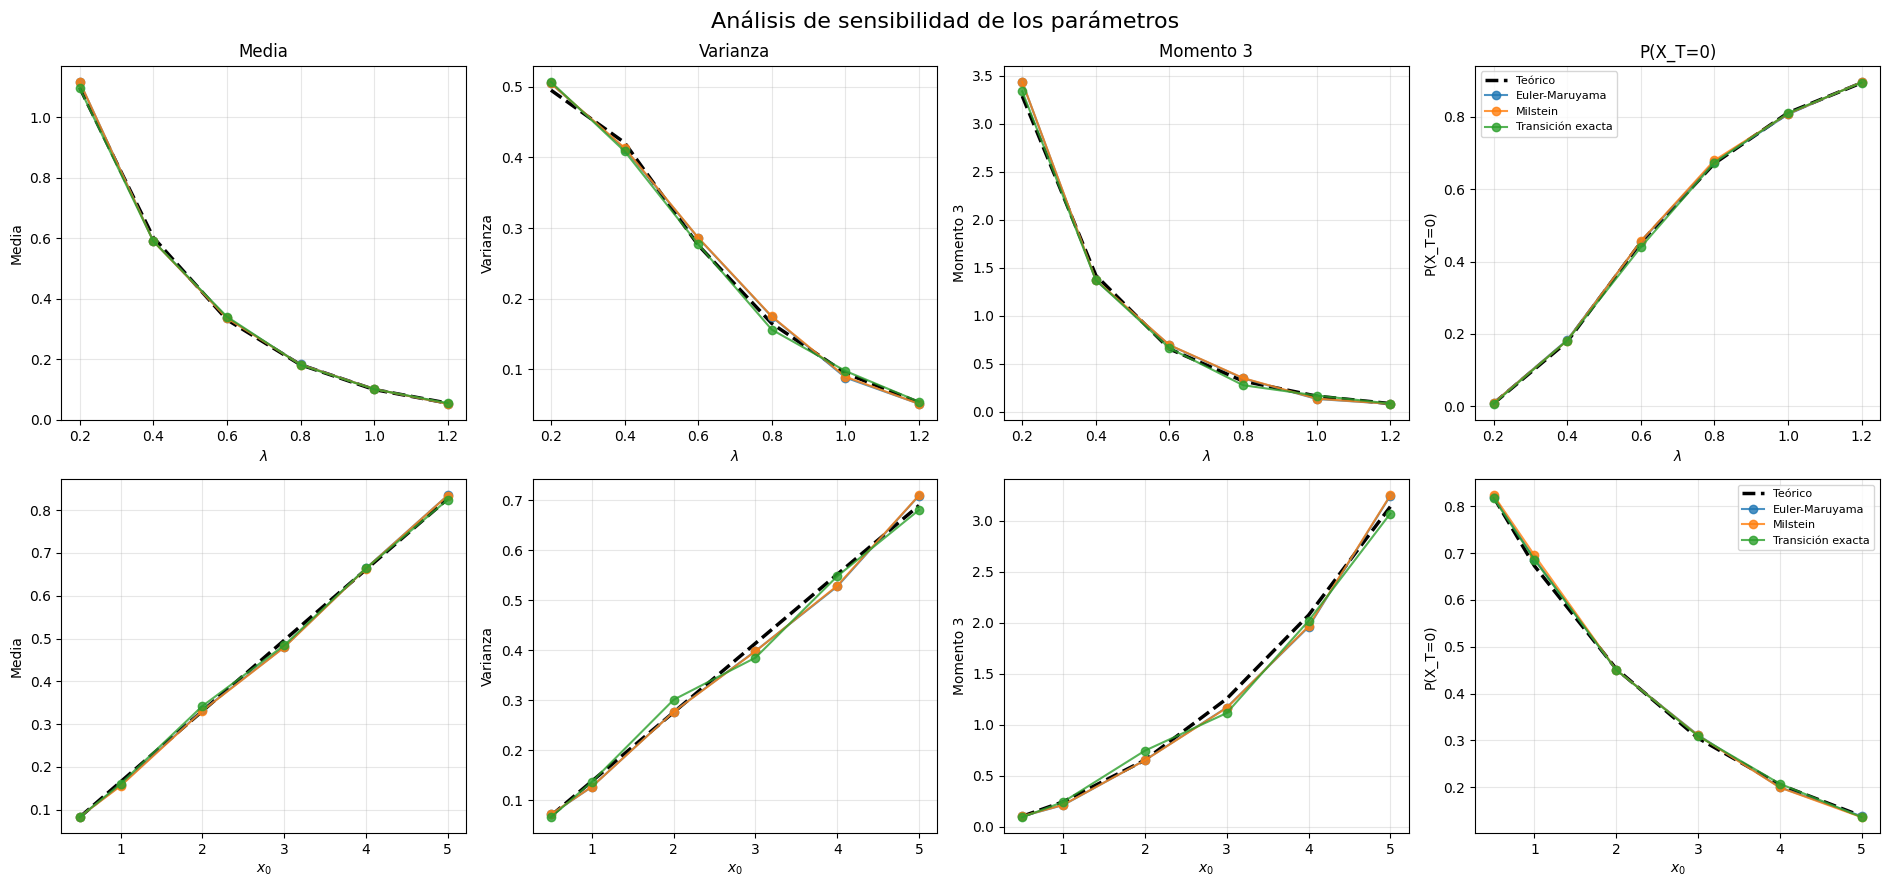

In [27]:

magnitudes = [
    "Media", "Varianza",
    "Momento 3", "P(X_T=0)"
]

fig, axes = plt.subplots(2, 4, figsize=(19, 9))

for i, parametro in enumerate(["lambda", "x0"]):

    for j, magnitud in enumerate(magnitudes):

        ax = axes[i, j]

        datos = tabla_sensibilidad[
            (tabla_sensibilidad["Parámetro"] == parametro)
            & (tabla_sensibilidad["Magnitud"] == magnitud)
        ]

        # Curva teórica
        referencia = (
            datos.drop_duplicates("Valor")
            .sort_values("Valor")
        )

        ax.plot(
            referencia["Valor"],
            referencia["Teórico"],
            "k--",
            linewidth=2.5,
            label="Teórico"
        )

        # Métodos de simulación
        for metodo, grupo in datos.groupby("Método"):

            grupo = grupo.sort_values("Valor")

            ax.plot(
                grupo["Valor"],
                grupo["Estimado"],
                marker="o",
                label=metodo,
                alpha=0.8
            )

        ax.set_xlabel(
            r"$\lambda$" if parametro == "lambda"
            else r"$x_0$"
        )
        ax.set_ylabel(magnitud)
        ax.grid(alpha=0.3)

        if i == 0:
            ax.set_title(magnitud)

        if j == 3:
            ax.legend(fontsize=8)

fig.suptitle(
    "Análisis de sensibilidad de los parámetros",
    fontsize=16
)

plt.tight_layout()
plt.show()


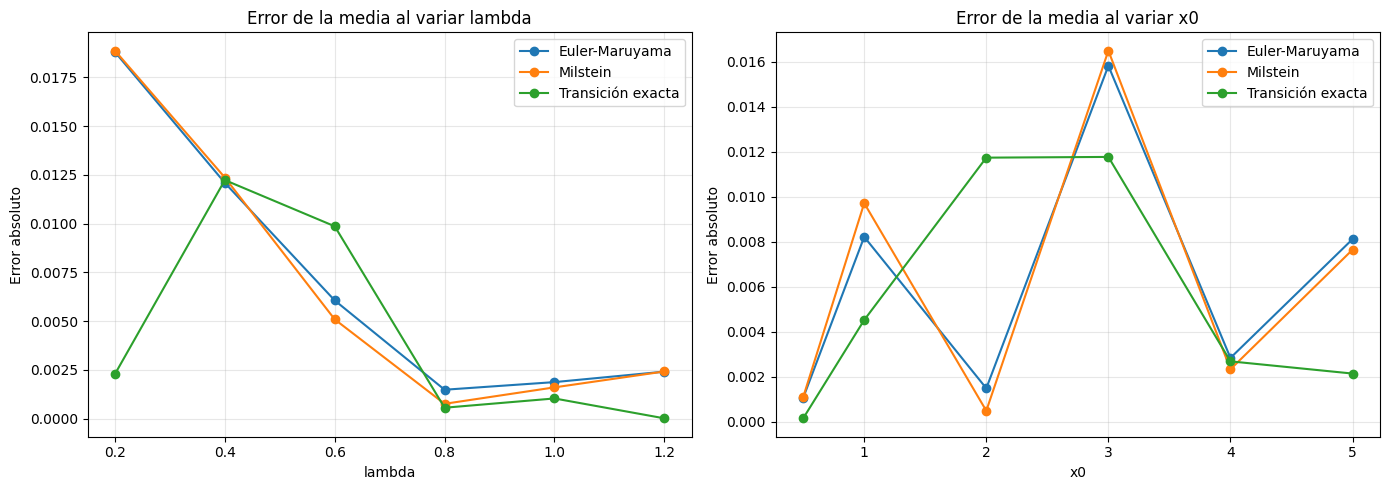

Método                    Euler-Maruyama  Milstein  Transición exacta
Parámetro Valor Magnitud                                             
lambda    0.2   Media            0.01880   0.01887            0.00228
                P(X_T=0)         0.00169   0.00149            0.00091
                Varianza         0.00958   0.00950            0.01167
          0.4   Media            0.01209   0.01236            0.01223
                P(X_T=0)         0.00486   0.00326            0.00326
                Varianza         0.00842   0.00751            0.01207
          0.6   Media            0.00606   0.00509            0.00986
                P(X_T=0)         0.00192   0.00312            0.01348
                Varianza         0.01019   0.01054            0.00113
          0.8   Media            0.00148   0.00076            0.00056
                P(X_T=0)         0.00486   0.00846            0.00226
                Varianza         0.00956   0.00998            0.00875
          1.0   Media            0.00187   0.00160            0.00103
                P(X_T=0)         0.00452   0.00292            0.00092
                Varianza         0.00619   0.00497            0.00313
          1.2   Media            0.00241   0.00241            0.00001
                P(X_T=0)         0.00248   0.00188            0.00068
                Varianza         0.00193   0.00190            0.00100
x0        0.5   Media            0.00106   0.00109            0.00015
                P(X_T=0)         0.00006   0.00346            0.00254
                Varianza         0.00241   0.00294            0.00305
          1.0   Media            0.00821   0.00971            0.00452
                P(X_T=0)         0.01504   0.02264            0.01324
                Varianza         0.01113   0.01101            0.00121
          2.0   Media            0.00148   0.00049            0.01173
                P(X_T=0)         0.00248   0.00228            0.00228
                Varianza         0.00136   0.00083            0.02513
          3.0   Media            0.01581   0.01648            0.01176
                P(X_T=0)         0.00663   0.00563            0.00443
                Varianza         0.01543   0.01591            0.02875
          4.0   Media            0.00283   0.00233            0.00268
                P(X_T=0)         0.00550   0.00590            0.00210
                Varianza         0.02417   0.02277            0.00375
          5.0   Media            0.00811   0.00764            0.00214
                P(X_T=0)         0.00042   0.00242            0.00222
                Varianza         0.01979   0.02026            0.00909

In [28]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, parametro in zip(
    axes, ["lambda", "x0"]
):

    datos = tabla_sensibilidad[
        (tabla_sensibilidad["Parámetro"] == parametro)
        & (tabla_sensibilidad["Magnitud"] == "Media")
    ]

    for metodo, grupo in datos.groupby("Método"):

        grupo = grupo.sort_values("Valor")

        ax.plot(
            grupo["Valor"],
            grupo["Error absoluto"],
            marker="o",
            label=metodo
        )

    ax.set_title(f"Error de la media al variar {parametro}")
    ax.set_xlabel(parametro)
    ax.set_ylabel("Error absoluto")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

# Comparación numérica de los errores
tabla_errores_sensibilidad = tabla_sensibilidad[
    tabla_sensibilidad["Magnitud"].isin([
        "Media", "Varianza", "P(X_T=0)"
    ])
].pivot_table(
    index=["Parámetro", "Valor", "Magnitud"],
    columns="Método",
    values="Error absoluto"
)

display(tabla_errores_sensibilidad.round(5))



### Sensibilidad analítica de las magnitudes del proceso

Además de comparar simulaciones, podemos estudiar la sensibilidad de las magnitudes teóricas mediante sus derivadas parciales respecto de los parámetros.

#### Sensibilidad de la media

Recordemos que

$$
\mathbb E[X_t]=x_0e^{-\lambda t}.
$$

Derivando respecto de $\lambda$ obtenemos

$$
\frac{\partial}{\partial\lambda}\mathbb E[X_t]
=
-tx_0e^{-\lambda t}<0,
\qquad t>0,\ x_0>0.
$$

Por tanto, al aumentar $\lambda$, la media disminuye más rápidamente. Por otro lado,

$$
\frac{\partial}{\partial x_0}\mathbb E[X_t]
=
e^{-\lambda t}>0.
$$

Esto muestra que la esperanza depende linealmente de la condición inicial.

#### Sensibilidad de la varianza

La varianza está dada por

$$
\operatorname{Var}(X_t)
=
x_0e^{-\lambda t}(1-e^{-\lambda t}).
$$

Derivando respecto de $\lambda$ obtenemos

$$
\frac{\partial}{\partial\lambda}
\operatorname{Var}(X_t)
=
tx_0e^{-\lambda t}
(2e^{-\lambda t}-1).
$$

A diferencia de la media, la varianza no necesariamente disminuye al aumentar $\lambda$. Para un tiempo fijo $t>0$, la varianza alcanza su máximo cuando

$$
\boxed{
\lambda t=\ln 2.
}
$$

En cambio, respecto de la condición inicial tenemos

$$
\frac{\partial}{\partial x_0}
\operatorname{Var}(X_t)
=
e^{-\lambda t}(1-e^{-\lambda t})>0.
$$

Por tanto, la varianza aumenta linealmente con $x_0$ para $t>0$.

#### Sensibilidad de la probabilidad de absorción

Sabemos que

$$
P_0(t)=\mathbb P(X_t=0)
=
\exp\left(
-\frac{2x_0}{e^{\lambda t}-1}
\right).
$$

Derivando respecto de $\lambda$ obtenemos

$$
\frac{\partial P_0(t)}{\partial\lambda}
=
P_0(t)
\frac{2x_0te^{\lambda t}}
{(e^{\lambda t}-1)^2}>0
$$

para $x_0>0$ y $t>0$.

Por lo tanto, al aumentar $\lambda$, aumenta la probabilidad de que el proceso haya sido absorbido en cero antes del tiempo $t$.

Por otro lado,

$$
\frac{\partial P_0(t)}{\partial x_0}
=
-\frac{2}{e^{\lambda t}-1}P_0(t)<0.
$$

Esto indica que comenzar desde un valor inicial mayor reduce la probabilidad de absorción antes de un tiempo fijo.

### Interpretación de los experimentos

El análisis permite identificar los siguientes efectos:

**Variaciones de $\lambda$.** Un aumento de este parámetro acelera el decaimiento de la media e incrementa la probabilidad de absorción en cero. La varianza presenta un comportamiento no monótono, debido a la interacción entre el decaimiento y las fluctuaciones estocásticas.

**Variaciones de $x_0$.** Una condición inicial mayor incrementa la media y la varianza en cualquier tiempo fijo positivo, mientras que disminuye la probabilidad de que el proceso ya haya sido absorbido.

**Comparación de métodos.** Los tres métodos deberían reproducir estas tendencias generales. Las diferencias entre las estimaciones y las curvas teóricas permiten identificar posibles errores de discretización y fluctuaciones de Monte Carlo. Finalmente, aunque los parámetros modifican la rapidez de la evolución y la distribución del proceso a tiempos finitos, para cualquier $\lambda>0$ y condición inicial $x_0\geq0$ se mantiene el comportamiento asintótico

$$
\boxed{
X_t\xrightarrow[t\to\infty]{d}0,
\qquad \pi=\delta_0.
}
$$

Así, los parámetros modifican la velocidad con la que el proceso se aproxima a su distribución estacionaria, pero no la distribución estacionaria misma.
